# m10 - Grid Networks: Does Spatial Context Help a Deep Model?

The 1 km cells sit on a 136 x 186 grid, so the province can be fed to a convolutional network as an image whose channels are the
14 physical drivers (plus a validity mask). Labels exist only for the cells of the training folds (the loss is masked to them);
inputs are visible everywhere, as they would be when the model is deployed over the whole province.

* **Pointwise** network: 1 x 1 convolutions only, equivalent to a per-cell MLP (no neighbours).
* **U-Net** (depth 2 and 3, 3 x 3 convolutions): sees a neighbourhood of roughly 10 and 22 km.

Scored with the pixel-grouped CV (5 folds x 2 repeats) and compared with the tree models of m01. A last check compares the
local (within-pixel) pattern of the predictions with the independent 1 km GCS 2024 product.

In [1]:
import torch  # noqa: F401  - keep first (see exp_lib docstring)
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
import exp_torch as T
print('device:', T.DEVICE, torch.cuda.get_device_name(0) if T.DEVICE == 'cuda' else '')

device: cuda NVIDIA GeForce RTX 5060


In [2]:
df = E.load_table()
targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}   # GAEZ v5 at 1 km (E.TARGET_RES)
log, oofs = [], {}

def run(name, cfg):
    res, oof = T.cv_grid(df, targets, {**cfg, "steps": 1000}, n_repeats=2)
    log.append({"setting": name, "r2": res["r2"].mean(), "spearman": res["spearman"].mean(), "rmse": res["rmse"].mean(),
                "seconds_per_repeat": res["fit_seconds"].iloc[0]})
    oofs[name] = oof
    print(f"{name:20s} R2={log[-1]['r2']:.3f}  rho={log[-1]['spearman']:.3f}  ({log[-1]['seconds_per_repeat']:.0f}s/repeat)", flush=True)

run("pointwise 64-64", dict(arch="pointwise", hidden=(64, 64)))
run("U-Net depth 2", dict(arch="unet", depth=2))
run("U-Net depth 3", dict(arch="unet", depth=3))

pointwise 64-64      R2=0.774  rho=0.879  (13s/repeat)


U-Net depth 2        R2=0.790  rho=0.893  (39s/repeat)


U-Net depth 3        R2=0.791  rho=0.891  (51s/repeat)


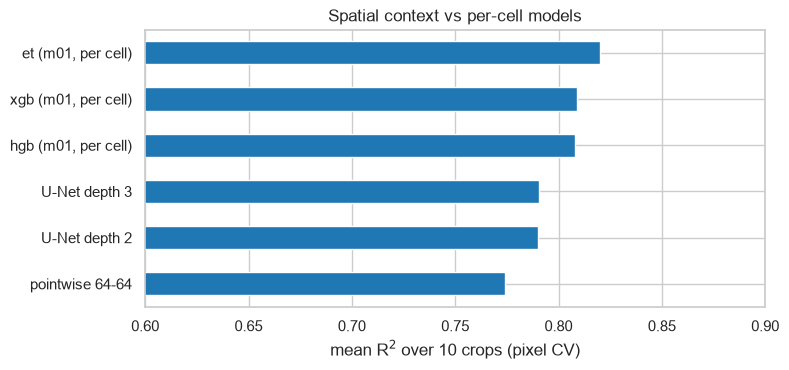

,r2,spearman,rmse
pointwise 64-64,0.774,0.879,979.247
U-Net depth 2,0.790,0.893,941.846
U-Net depth 3,0.791,0.891,940.210
"et (m01, per cell)",0.820,0.902,873.098
"hgb (m01, per cell)",0.808,0.897,901.163
"xgb (m01, per cell)",0.809,0.896,899.598


In [3]:
ref = pd.read_csv(E.RESULTS_DIR / "m01_baselines_raw.csv")
ref = ref[ref.scheme == "pixel"].groupby("model")[["r2", "spearman", "rmse"]].mean().loc[["et", "hgb", "xgb"]]
full = pd.concat([pd.DataFrame(log).set_index("setting")[["r2", "spearman", "rmse"]], ref.rename(index=lambda m: f"{m} (m01, per cell)")])
E.save_table(full.round(4), "m10_grid_networks", index=True)
fig, ax = plt.subplots(figsize=(8, 3.6))
full["r2"].sort_values().plot.barh(ax=ax, color="tab:blue")
ax.set(xlabel="mean R$^2$ over 10 crops (pixel CV)", ylabel="", xlim=(0.6, 0.9), title="Spatial context vs per-cell models")
E.save_fig(fig, "m10_context")
plt.show()
full.round(3)

## What the predictions look like
Out-of-fold predictions for two crops: the GAEZ 1 km target, a per-cell model and the U-Net.

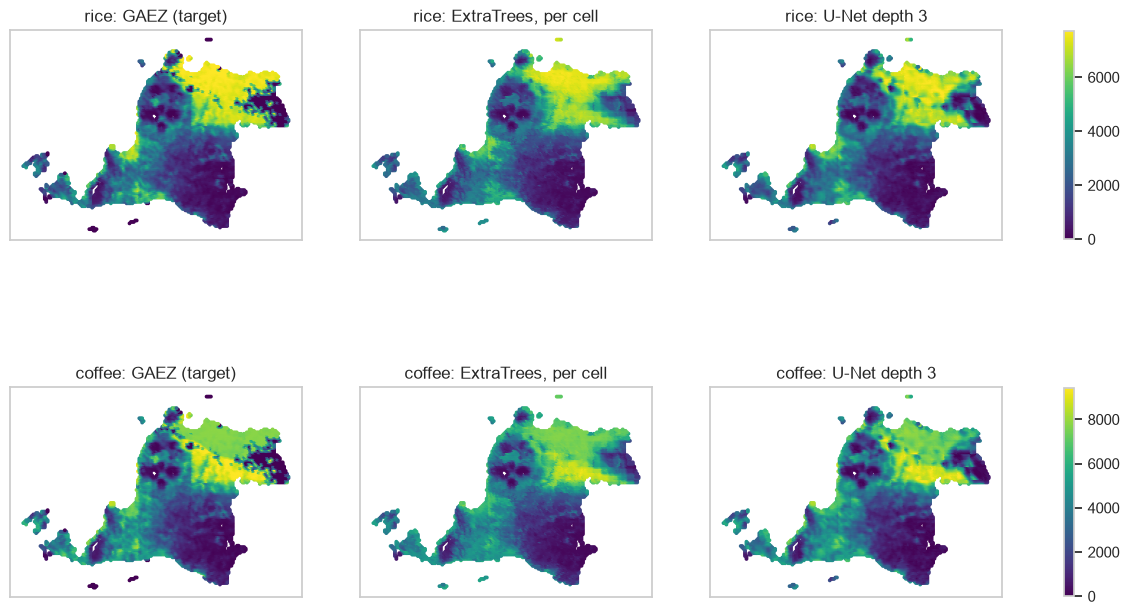

In [4]:
et_pred = pd.read_parquet(E.OOF_DIR / "m01_oof_pixel.parquet")
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for row_i, crop in enumerate(["rice", "coffee"]):
    j = E.CROPS.index(crop)
    panels = [("GAEZ (target)", targets[crop]), ("ExtraTrees, per cell", et_pred[f"et__{crop}"].to_numpy()),
              ("U-Net depth 3", oofs["U-Net depth 3"][:, :, j].mean(axis=0))]
    for ax, (title, v) in zip(axes[row_i], panels):
        sc = ax.scatter(df["lon"], df["lat"], c=v, s=3, cmap="viridis", vmin=0, vmax=np.nanpercentile(targets[crop], 99))
        ax.set(title=f"{crop}: {title}", aspect="equal"); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=axes[row_i], shrink=0.7)
E.save_fig(fig, "m10_maps")
plt.show()

## Local detail against the independent 1 km product
Spearman correlation of within-pixel departures (cell minus the mean of its ~9 km GAEZ pixel) with the GCS 2024
product. The GAEZ target itself is the reference: a model of GAEZ cannot be expected to match GCS better than GAEZ does.

In [5]:
ok = df[E.gcs_cols()].notna().all(axis=1).to_numpy()
def demean(v):
    return v - pd.Series(v).groupby(df["pix"].to_numpy()).transform("mean").to_numpy()
rows = []
for c in E.GCS_CROPS:
    j = E.CROPS.index(c)
    ref_a = demean(df[f"gcs2024_{c}"].fillna(df[f"gcs2024_{c}"].median()).to_numpy())[ok]
    entry = {"crop": c, "GAEZ 1 km (target)": E.spearman(demean(targets[c])[ok], ref_a),
             "ExtraTrees per cell": E.spearman(demean(et_pred[f"et__{c}"].to_numpy())[ok], ref_a)}
    for name in ("pointwise 64-64", "U-Net depth 2", "U-Net depth 3"):
        entry[name] = E.spearman(demean(oofs[name][:, :, j].mean(axis=0))[ok], ref_a)
    rows.append(entry)
sub = pd.DataFrame(rows).set_index("crop")
E.save_table(sub.round(4), "m10_subpixel_vs_gcs", index=True)
sub.round(3)

,GAEZ 1 km (target),ExtraTrees per cell,pointwise 64-64,U-Net depth 2,U-Net depth 3
crop,,,,,
rice,0.435,0.468,0.439,0.399,0.416
maize,-0.036,0.035,0.022,0.013,0.014
cassava,0.244,0.123,0.104,0.116,0.117
soybean,-0.080,-0.044,-0.039,-0.040,-0.036
oilpalm,0.158,0.202,0.209,0.164,0.182
sugarcane,0.320,0.260,0.208,0.231,0.250
